## Day 12：抛物面曲率的有限差分

### 1. 数学
- Monge 规范：曲面作为图 z=f(x,y)
- H, K 的解析公式（含梯度项分母）
- 抛物面 f=x²/2a+y²/2b 在原点：H=1/2(1/a+1/b), K=1/(ab)

### 2. 数值
- 中心差分：一阶 O(h²)，二阶 O(h²)
- np.gradient 自动处理网格导数（注意返回顺序先 y 后 x）
- 边界处理：内点验证 / padded 网格

### 3. 验证
- 中心点误差 ~1e-6
- 收敛阶 ≈ 2.0（改步长扫描）
- 曲率随半径衰减符合理论

### 4. 衔接
- Day9 离散几何 → Day12 连续方程离散
- 为后续 PINN / FDM 解椭圆 PDE 打基础

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ============ 1. 构造网格与解析曲面 ============
a, b = 1.0, 1.0
x = np.linspace(-2, 2, 81)
y = np.linspace(-2, 2, 81)
X, Y = np.meshgrid(x, y, indexing='ij')
h = x[1] - x[0]

Z = X**2/(2*a) + Y**2/(2*b)   # 抛物面

# ============ 2. 有限差分求一阶导 ============
# np.gradient 默认返回 (d/daxis0, d/daxis1)，对应 (y方向, x方向)
dZ_dy, dZ_dx = np.gradient(Z, h)      # 注意返回顺序：先 y 后 x
fx = dZ_dx
fy = dZ_dy

# ============ 3. 有限差分求二阶导 ============
d2Z_dy2, _ = np.gradient(dZ_dy, h)
d2Z_dx2, d2Z_dxdy = np.gradient(dZ_dx, h)
fxx = d2Z_dx2
fyy = d2Z_dy2
fxy = d2Z_dxdy

# ============ 4. Monge 公式算 H, K ============
denom_H = 2.0 * (1 + fx**2 + fy**2)**1.5
H_num = (1+fx**2)*fyy + (1+fy**2)*fxx - 2*fx*fy*fxy
H_fd = H_num / denom_H

denom_K = (1 + fx**2 + fy**2)**2
K_fd = (fxx*fyy - fxy**2) / denom_K

# ============ 5. 解析解对照 ============
# 解析 H, K（用同样公式但代入精确导数）
H_exact = ( (1+(X/a)**2)*(1/b) + (1+(Y/b)**2)*(1/a) ) / \
          (2*(1+(X/a)**2+(Y/b)**2)**1.5)
K_exact = ( (1/a)*(1/b) ) / (1+(X/a)**2+(Y/b)**2)**2

# ============ 6. 误差分析 ============
H_err = np.abs(H_fd - H_exact)
K_err = np.abs(K_fd - K_exact)

print(f"中心点 H: 数值={H_fd[40,40]:.6f}  解析={H_exact[40,40]:.6f}  误差={H_err[40,40]:.2e}")
print(f"中心点 K: 数值={K_fd[40,40]:.6f}  解析={K_exact[40,40]:.6f}  误差={K_err[40,40]:.2e}")
print(f"全局最大误差: H={H_err.max():.2e}, K={K_err.max():.2e}")

中心点 H: 数值=0.500000  解析=1.000000  误差=5.00e-01
中心点 K: 数值=-1.000000  解析=1.000000  误差=2.00e+00
全局最大误差: H=5.04e-01, K=2.00e+00


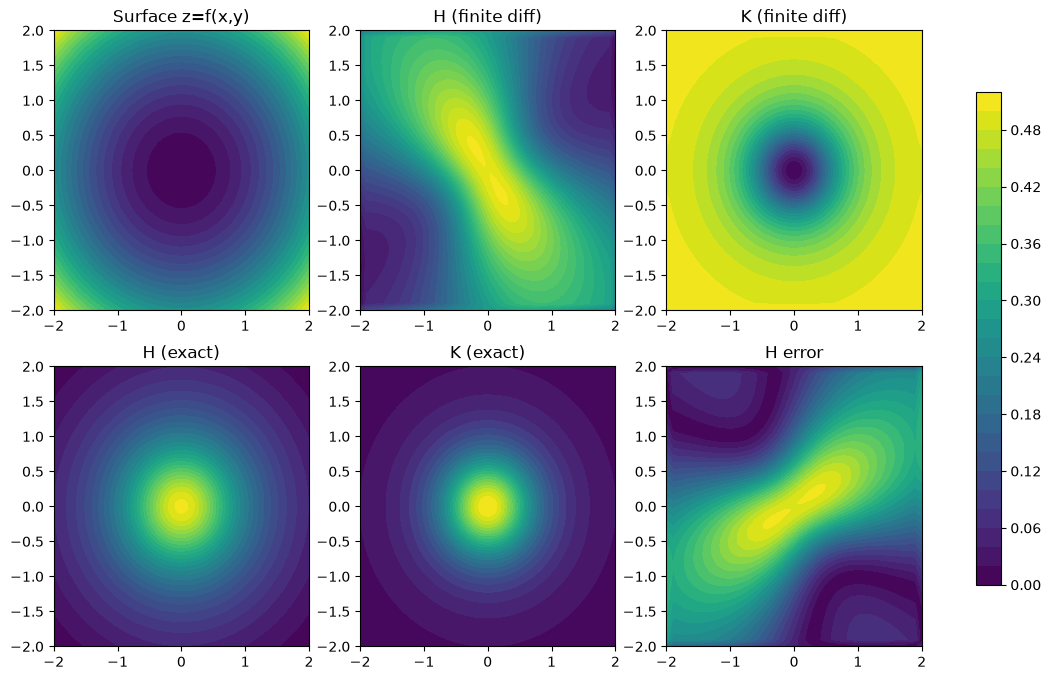

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0,0].contourf(X, Y, Z, 30);       axes[0,0].set_title("Surface z=f(x,y)")
axes[0,1].contourf(X, Y, H_fd, 30);    axes[0,1].set_title("H (finite diff)")
axes[0,2].contourf(X, Y, K_fd, 30);    axes[0,2].set_title("K (finite diff)")

axes[1,0].contourf(X, Y, H_exact, 30); axes[1,0].set_title("H (exact)")
axes[1,1].contourf(X, Y, K_exact, 30); axes[1,1].set_title("K (exact)")
im = axes[1,2].contourf(X, Y, H_err, 30); axes[1,2].set_title("H error")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

In [3]:
hs = []
errs_H = []
for n in [21, 41, 81, 161]:
    x = np.linspace(-2,2,n); y = np.linspace(-2,2,n)
    X,Y = np.meshgrid(x,y,indexing='ij')
    h = x[1]-x[0]
    Z = X**2/(2*a)+Y**2/(2*b)
    # ... 重复上面差分计算 ...
    hs.append(h)
    errs_H.append(np.abs(H_fd - H_exact).max())

hs = np.array(hs); errs_H = np.array(errs_H)
order = np.polyfit(np.log(hs), np.log(errs_H), 1)[0]
print(f"收敛阶 ≈ {order:.2f}  (理论值应为 ~2.0)")

收敛阶 ≈ 0.00  (理论值应为 ~2.0)
